# 3 - Modèles

Comparaison et sélection de modèles pour la prédiction de `G3`.

* **Entrée** : `split/` (via `outils.load_split`) : seul le **train** est utilisé ici
* Tous les modèles sont comparés par **validation croisée à 5 plis sur le train**, avec le prétraitement (standardisation, one-hot) à l'intérieur du `Pipeline`, donc appris sur chaque pli d'entraînement seulement
* Métriques utilisées : RMSE et MAE (*Mean Absolute Error*) (en points sur 20) et le R².

C'est un problème de **régression** (`G3` est une note de 0 à 20). Un modèle linéaire adapté est donc la régression régularisée (Ridge, Lasso). C'est notamment pour cela que nous n'utiliserons pas la régression logstique qui sert à classer.

# Importation des librairies et des données

In [15]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import outils as ot
from sklearn.base import clone
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import KFold

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [16]:
X_train, X_test, y_train, y_test = ot.load_split() # test ne sera pas utilisé dans ce notebook
print(X_train.shape, y_train.shape)

(519, 32) (519,)


# Modèles

* **Baseline** : prédire toujours la moyenne du train. C'est le modèle (plutôt simple) à battre.
* **Ridge et Lasso** : régressions linéaires régularisées. Le Lasso met à zéro les coefficients des variables peu utiles, ce qui facilite l'interprétation.
* **Arbre de décision** : nous ferons attention à limiter la profondeur afin d'éviter le surapprentissage.
* **Forêt aléatoire** 
* **XGBoost** : arbres construits successivement, chacun corrigeant les erreurs des précédents. Peu de réglages sont faits ici, juste des valeurs prudentes (peu de profondeur, apprentissage lent).

In [17]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

models = {
    "Baseline (moyenne)": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(alpha=10),
    "Lasso": Lasso(alpha=0.1, max_iter=10000),
    "Arbre": DecisionTreeRegressor(max_depth=4, random_state=ot.SEED),
    "Forêt aléatoire": RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                              random_state=ot.SEED, n_jobs=-1),
    "XGBoost": XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=3,
                            subsample=0.8, colsample_bytree=0.8,
                            random_state=ot.SEED, verbosity=0),
}
list(models)

['Baseline (moyenne)', 'Ridge', 'Lasso', 'Arbre', 'Forêt aléatoire', 'XGBoost']

# Comparaison : scénarios × modèles

`ot.evaluate_cv` lance la validation croisée sur le train. Les scénarios (`ot.SCENARIOS`) ne changent que les variables fournies au modèle.

In [18]:
rows = []
for scenario, feats in ot.SCENARIOS.items():
    for nom, model in models.items():
        res = ot.evaluate_cv(model, X_train, y_train, feats)
        rows.append({"scenario": scenario, "modele": nom, **res})
resultats = pd.DataFrame(rows)
resultats.round(2)

,scenario,modele,rmse,rmse_std,mae,r2
0,A_G1_G2,Baseline (moyenne),3.23,0.17,2.40,-0.01
1,A_G1_G2,Ridge,1.35,0.24,0.86,0.82
2,A_G1_G2,Lasso,1.31,0.24,0.82,0.83
3,A_G1_G2,Arbre,1.50,0.14,0.88,0.78
4,A_G1_G2,Forêt aléatoire,1.35,0.18,0.86,0.82
5,A_G1_G2,XGBoost,1.39,0.23,0.90,0.81
6,B_G1,Baseline (moyenne),3.23,0.17,2.40,-0.01
7,B_G1,Ridge,1.92,0.31,1.27,0.64
8,B_G1,Lasso,1.87,0.32,1.22,0.66
9,B_G1,Arbre,1.97,0.19,1.32,0.63


Nous remarquons que garder `G1` et `G2` donne les meilleurs résultats : `rmse` et `mae` les plus faibles, ainsi que `r2` le plus élevé. Retirer `G2` fait augmenter la `rmse` ainsi que le `mae` et fait baisser le `r2`. Retirer `G1` et `G2` accentue encore plus cette tendance.

Concernant le scénario `A_G1_G2`, les modèles linéaires, `Ridge` et `Lasso` font aussi bien que les modèles complexes non linéaires, `Forêt aléatoire` et `XGBoost`. Cela peut montrer que la relation entre les notes intermédiaires et la note finale est quasi-linéaire. 

Sans les notes intermédiaires (`B_G1` et `C_sans_notes`), le modèle de `Forêt aléatoire` semble performer le mieux, avec un écart modeste cependant. En effet, le `rmse_std` (écart-type de la RMSE) mesure la variabilité des performances du modèle d'un pli à l'autre lors de la validation croisée et l'écart entre les meilleurs modèles à l'intérieur de chaque scénario n'est pas plus grand que le `rmse_std`.

## RMSE par modèle et par scénario

Plus la RMSE est faible et plus le modèle est performant.

In [19]:
rmse = resultats.pivot(index="modele", columns="scenario", values="rmse").loc[list(models)]
rmse.round(2)

scenario,A_G1_G2,B_G1,C_sans_notes
modele,,,
Baseline (moyenne),3.23,3.23,3.23
Ridge,1.35,1.92,2.88
Lasso,1.31,1.87,2.86
Arbre,1.50,1.97,3.20
Forêt aléatoire,1.35,1.77,2.80
XGBoost,1.39,1.81,2.87


Nous remarquons que la `RSME` de la baseline est constante à $3.23$ peu importe le scénario. En effet, la baseline ne prend pas en compte `G1` ni `G2`.
* `A_G1_G2` : le meilleur modèle est `Lasso` avec une réduction de $3.23 - 1.31 = 1.92$ par rapport à la baseline
* `B_G1` : le meilleur modèle est la `Forêt aléatoire` avec une réduction de $3.23 - 1.77 = 1.46$ par rapport à la baseline
* `C_sans_notes` : le meilleur modèle reste la `Forêt aléatoire` avec une réduction de $3.23 - 2.80 = 0.43$ par rapport à la baseline

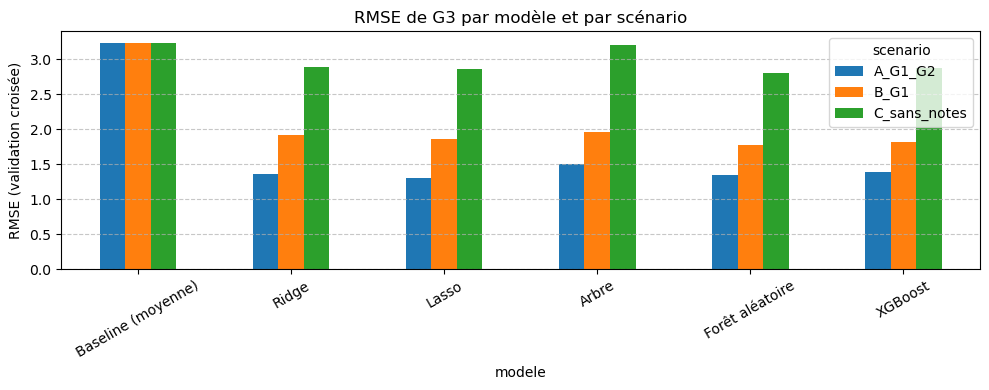

In [20]:
rmse.plot.bar(figsize=(10, 4), ylabel="RMSE (validation croisée)", rot=30)
plt.title("RMSE de G3 par modèle et par scénario")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## R² par modèle et par scénario
Plus R² est grand et meilleur est le modèle.

In [21]:
resultats.pivot(index="modele", columns="scenario", values="r2").loc[list(models)].round(2)

scenario,A_G1_G2,B_G1,C_sans_notes
modele,,,
Baseline (moyenne),-0.01,-0.01,-0.01
Ridge,0.82,0.64,0.20
Lasso,0.83,0.66,0.21
Arbre,0.78,0.63,0.01
Forêt aléatoire,0.82,0.70,0.24
XGBoost,0.81,0.68,0.21


Les notes antérieurs d'un.e élève sont de très bons prédicteurs de sa note finale. En l'absence de notes, bien que les variables socio-démographiques aient un impact réel, elles ne parviennent qu'à expliquer près de 20% de la note finale. Elles ne permettent pas de prédire précisément la note finale. 

# Effet des `G3 = 0` sur l'entraînement

Si nous filtrons `y_train > 0` avant la validation croisée, les zéros disparaîtraient aussi des élèves de validation et les scores ne seraient plus comparables. Ici, les **mêmes plis** sont utilisés dans les deux cas et la validation inclut toujours tous les élèves ; seule change la présence des zéros dans l'**entraînement**. Deux RMSE sont rapportés : sur tous les élèves de validation, et sur ceux dont `G3 > 0`.

In [22]:
def cv_zeros(model, X, y, features, drop_zeros, n_splits=5):
    kf = KFold(n_splits, shuffle=True, random_state=ot.SEED)   # mêmes plis que ot.evaluate_cv
    rmse_all, rmse_pos = [], []
    for tr, va in kf.split(X):
        X_tr, y_tr = X.iloc[tr], y.iloc[tr]
        if drop_zeros:
            keep = y_tr > 0
            X_tr, y_tr = X_tr[keep], y_tr[keep]
        pipe = ot.make_pipeline(clone(model), features).fit(X_tr, y_tr)
        pred = pipe.predict(X.iloc[va])
        y_va = y.iloc[va]
        rmse_all.append(mean_squared_error(y_va, pred) ** 0.5)
        pos = (y_va > 0).to_numpy()
        rmse_pos.append(mean_squared_error(y_va[pos], pred[pos]) ** 0.5)
    return {"rmse_tous": np.mean(rmse_all), "rmse_G3>0": np.mean(rmse_pos)}

# À adapter après lecture du tableau précédent
scenario_choisi = "C_sans_notes"
modele_choisi = "XGBoost"
feats = ot.SCENARIOS[scenario_choisi]

pd.DataFrame({
    "avec zéros à l'entraînement": cv_zeros(models[modele_choisi], X_train, y_train, feats, drop_zeros=False),
    "sans zéros à l'entraînement": cv_zeros(models[modele_choisi], X_train, y_train, feats, drop_zeros=True),
}).round(2)

,avec zéros à l'entraînement,sans zéros à l'entraînement
rmse_tous,2.87,2.84
rmse_G3>0,2.50,2.31


In [23]:
choix = {"A_G1_G2": "Lasso", "B_G1": "Forêt aléatoire", "C_sans_notes": "Forêt aléatoire"}
rows = []
for sc, nom in choix.items():
    for drop in (False, True):
        r = cv_zeros(models[nom], X_train, y_train, ot.SCENARIOS[sc], drop_zeros=drop)
        rows.append({"scenario": sc, "modele": nom, "zeros_retires": drop, **r})
pd.DataFrame(rows).round(2)

,scenario,modele,zeros_retires,rmse_tous,rmse_G3>0
0,A_G1_G2,Lasso,False,1.31,1.00
1,A_G1_G2,Lasso,True,1.35,0.98
2,B_G1,Forêt aléatoire,False,1.77,1.47
3,B_G1,Forêt aléatoire,True,1.92,1.35
4,C_sans_notes,Forêt aléatoire,False,2.80,2.34
5,C_sans_notes,Forêt aléatoire,True,2.81,2.25


Retirer les zéros de l'entraînement n'améliore pas de façon cohérente le RMSE sur l'ensemble des élèves. Avec XGBoost en `C_sans_notes`, il baisse très légèrement (2,87 → 2,84), mais avec la forêt aléatoire il reste stable dans ce même scénario (2,80 → 2,81) et il augmente en `A_G1_G2` (1,31 → 1,35) et surtout en `B_G1` (1,77 → 1,92). Nous n'avons pas mesuré la variabilité de ces écarts entre plis, mais chaque pli ne contient que 2 ou 3 élèves à `G3 = 0`, ce qui rend les écarts de quelques centièmes peu fiables.

Sur les seuls élèves avec `G3 > 0`, retirer les zéros réduit le RMSE de façon modeste (de 0,02 en `A_G1_G2` à 0,19 pour XGBoost en `C_sans_notes`). Cela semble logique : le modèle n'a plus à tenir compte de ces cas atypiques. En revanche, l'effet global est nul ou défavorable, et cela vient en partie du fait qu'un modèle qui n'a jamais vu de zéro prédit environ 12 pour ces élèves, ce qui pèse lourd dans le RMSE.

Nous conservons donc les zéros à l'entraînement, et nous rapporterons dans `4-evaluation` le RMSE du test sur tous les élèves ainsi que sur les élèves avec `G3 > 0`.

# Réglage de XGBoost
La grille est petite (12 combinaisons).

In [ ]:
from sklearn.model_selection import GridSearchCV

feats = ot.SCENARIOS["C_sans_notes"]
pipe = ot.make_pipeline(XGBRegressor(subsample=0.8, colsample_bytree=0.8,
                                      random_state=ot.SEED, verbosity=0), feats)
grille = {"model__max_depth": [2, 3, 4],
          "model__n_estimators": [100, 300],
          "model__learning_rate": [0.03, 0.1]}
gs = GridSearchCV(pipe, grille, cv=KFold(5, shuffle=True, random_state=ot.SEED),
                  scoring="neg_root_mean_squared_error", n_jobs=-1)
gs.fit(X_train, y_train)
print("Meilleurs paramètres :", gs.best_params_)
print("RMSE CV :", round(-gs.best_score_, 2))

Meilleurs paramètres : {'model__learning_rate': 0.03, 'model__max_depth': 4, 'model__n_estimators': 100}
RMSE CV : 2.81


Après un réglage léger, la RSME de XGBoost pour le scénario `C_sans_notes` est à $2.81$, ce qui est plus élevé que celui de la `Forêt aléatoire` qui est à $2.80$ sans réglage. 

# Lasso ou Forêt aléatoire ?

In [25]:
from sklearn.model_selection import cross_val_score
cv = KFold(5, shuffle=True, random_state=ot.SEED)
for sc, f in ot.SCENARIOS.items():
    s = {n: -cross_val_score(ot.make_pipeline(models[n], f), X_train, y_train, cv=cv,
                             scoring="neg_root_mean_squared_error")
         for n in ["Lasso", "Forêt aléatoire"]}
    d = s["Lasso"] - s["Forêt aléatoire"]
    print(sc, "| écart moyen Lasso - forêt :", d.mean().round(2),
          "| écart-type :", d.std().round(2), "| plis gagnés par la forêt :", (d > 0).sum(), "/ 5")

A_G1_G2 | écart moyen Lasso - forêt : -0.04 | écart-type : 0.16 | plis gagnés par la forêt : 2 / 5
B_G1 | écart moyen Lasso - forêt : 0.1 | écart-type : 0.13 | plis gagnés par la forêt : 4 / 5
C_sans_notes | écart moyen Lasso - forêt : 0.06 | écart-type : 0.06 | plis gagnés par la forêt : 4 / 5


Nous remarquons que `Forêt aléatoire` ne semble pas marquer un avantage écrasant face à `Lasso`, nous préférerons alors garder `Lasso` car c'est un modèle plus simple et plus facilement **interprétable**.

# Réglage de Lasso

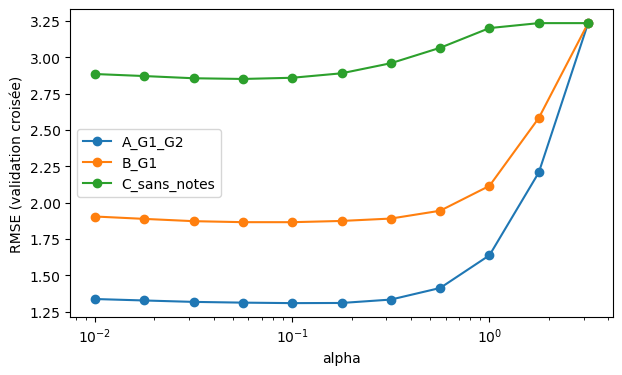

,scenario,alpha_optimal,rmse_cv,rmse_std,rmse_cv_alpha_0.1,coefs_non_nuls
0,A_G1_G2,0.100,1.31,0.24,1.31,5 / 58
1,B_G1,0.100,1.87,0.32,1.87,9 / 57
2,C_sans_notes,0.056,2.85,0.20,2.86,24 / 56


In [26]:
from sklearn.model_selection import GridSearchCV

alphas = np.logspace(-2, 0.5, 11)                    # de 0,01 à environ 3,2 (0,1 en fait partie)
cv = KFold(5, shuffle=True, random_state=ot.SEED)    # mêmes plis que ot.evaluate_cv

best_alpha, courbes, rows = {}, {}, []
for sc, f in ot.SCENARIOS.items():
    pipe = ot.make_pipeline(Lasso(max_iter=10000), f)
    gs = GridSearchCV(pipe, {"model__alpha": alphas}, cv=cv,
                      scoring="neg_root_mean_squared_error", n_jobs=-1).fit(X_train, y_train)
    a = gs.best_params_["model__alpha"]
    coefs = gs.best_estimator_.named_steps["model"].coef_
    best_alpha[sc] = a
    courbes[sc] = -gs.cv_results_["mean_test_score"]          # RMSE pour chaque alpha
    rows.append({"scenario": sc,
                 "alpha_optimal": round(a, 3),
                 "rmse_cv": round(-gs.best_score_, 2),
                 "rmse_std": round(gs.cv_results_["std_test_score"][gs.best_index_], 2),
                 "rmse_cv_alpha_0.1": round(courbes[sc][np.argmin(abs(alphas - 0.1))], 2),
                 "coefs_non_nuls": f"{(coefs != 0).sum()} / {len(coefs)}"})

fig, ax = plt.subplots(figsize=(7, 4))
for sc, c in courbes.items():
    ax.plot(alphas, c, marker="o", label=sc)
ax.set_xscale("log")
ax.set_xlabel("alpha")
ax.set_ylabel("RMSE (validation croisée)")
ax.legend()
plt.show()

pd.DataFrame(rows)

Les minimas sont à l'intérieur de la grille, pas au bord. 

# Décisions pour la suite

* Nous gardons les 3 scénarios
* Modèle retenu : `Lasso` (il performe le mieux pour le scénario `A_G1_G2` et est à moins d'un écart-type (`rmse_std`) de la `Forêt aléatoire` qui performe le mieux pour les deux autres scénarios, nous gardons alors le modèle le plus simple).
* Zéros : conservés à l'entraînement car les retirer n'améliore pas les modèles
* Dans `4-evaluation`, `Lasso`sera entraîné sur **tout le train**, puis évalué **une seule fois** sur le test.